Dataset Shape: (4998, 141)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,316 (87.17 KB)

 Trainable params: 22,316 (87.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6978 - mae: 0.5973 - val_loss: 0.3993 - val_mae: 0.4533
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3238 - mae: 0.3996 - val_loss: 0.2546 - val_mae: 0.3512
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2455 - mae: 0.3428 - val_loss: 0.2049 - val_mae: 0.3133
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1989 - mae: 0.3059 - val_loss: 0.1704 - val_mae: 0.2857
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1685 - mae: 0.2818 - val_loss: 0.1515 - val_mae: 0.2686
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1499 - mae: 0.2648 - val_loss: 0.1395 - val_mae: 0.2563
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1385 - mae: 0.2542 - val_loss: 0.1353 - val_mae: 0.2497
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1307 - mae: 0.2472 - val_loss: 0.1270 - val_mae: 0.2422
Epoch 9/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1237 - mae: 

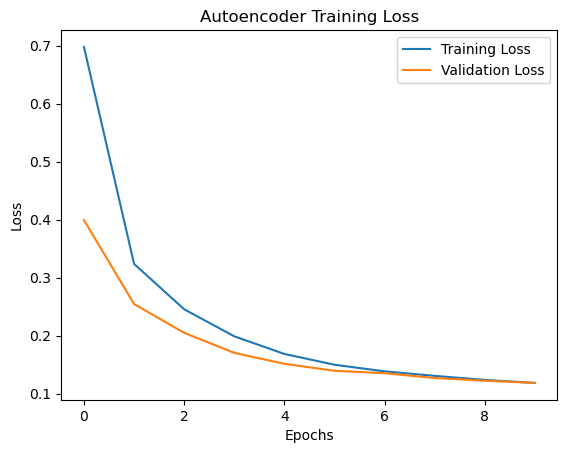

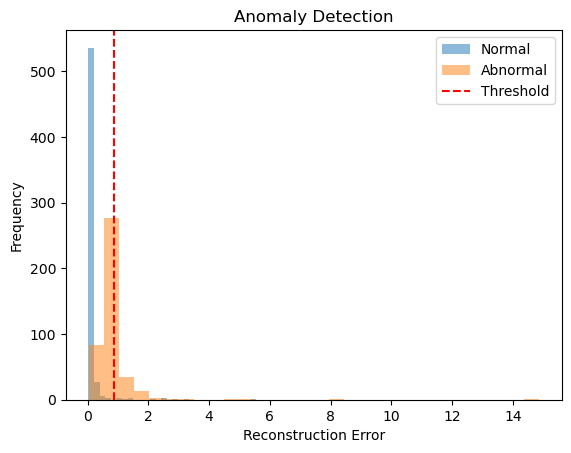

In [1]:
# Assignment 3E: Anomaly Detection Using Autoencoder

# Stage 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam


# Stage 2: Load Dataset

data = pd.read_csv("ecg.csv", header=None)

print("Dataset Shape:", data.shape)


# Separate features and labels
X = data.iloc[:, :-1].values

# ECG dataset:
# 1 = Normal
# 0 = Abnormal

# Convert:
# 0 = Normal
# 1 = Anomaly

y = (data.iloc[:, -1].values == 0).astype(int)


# Stage 3: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Stage 4: Select Only Normal Data

X_train_normal = X_train[y_train == 0]


# Stage 5: Scale Data

scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)


# Stage 6: Build Autoencoder

model = Sequential([
    Input(shape=(140,)),

    # Encoder
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    # Decoder
    Dense(64, activation="relu"),
    Dense(140, activation="linear")
])


# Stage 7: Compile Model

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


# Stage 8: Train Model

history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)


# Stage 9: Calculate Training Reconstruction Error

train_predictions = model.predict(
    X_train_normal,
    verbose=0
)

train_error = np.mean(
    np.square(X_train_normal - train_predictions),
    axis=1
)


# Stage 10: Set Threshold

threshold = np.percentile(train_error, 99)

print("Threshold:", threshold)


# Stage 11: Calculate Testing Reconstruction Error

test_predictions = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=1
)


# Stage 12: Detect Anomalies

y_pred = (test_error > threshold).astype(int)


# Stage 13: Evaluate Model

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Stage 14: Plot Training Loss

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()


# Stage 15: Plot Reconstruction Errors

plt.hist(test_error[y_test == 0], bins=30,
         alpha=0.5, label="Normal")

plt.hist(test_error[y_test == 1], bins=30,
         alpha=0.5, label="Abnormal")

plt.axvline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.title("Anomaly Detection")
plt.legend()
plt.show()